In [1]:
import pandas as pd

df = pd.read_csv(r"D:\CodexProjects\Delaney ESOL\delaney-processed.csv")

print(df.shape)
df.head()

(1128, 10)


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1


先只看这几列

In [2]:
cols = [
    "Molecular Weight",
    "Number of H-Bond Donors",
    "Number of Rings",
    "Number of Rotatable Bonds",
    "Polar Surface Area",
    "measured log solubility in mols per litre"
]

df[cols].head()

df[cols].describe()

,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre
count,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000,1128.000000
mean,203.937074,0.701241,1.390957,2.177305,34.872881,-3.050102
std,102.738077,1.089727,1.318286,2.640974,35.383593,2.096441
min,16.043000,0.000000,0.000000,0.000000,0.000000,-11.600000
25%,121.183000,0.000000,0.000000,0.000000,0.000000,-4.317500
50%,182.179000,0.000000,1.000000,1.000000,26.300000,-2.860000
75%,270.372000,1.000000,2.000000,3.000000,55.440000,-1.600000
max,780.949000,11.000000,8.000000,23.000000,268.680000,1.580000


单独看目标变量

In [3]:
target = "measured log solubility in mols per litre"

print(df[target].describe())

count    1128.000000
mean       -3.050102
std         2.096441
min       -11.600000
25%        -4.317500
50%        -2.860000
75%        -1.600000
max         1.580000
Name: measured log solubility in mols per litre, dtype: float64


目标变量分布情况

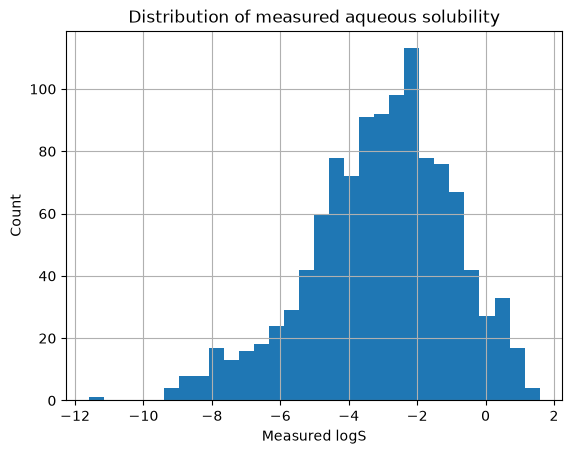

In [4]:
import matplotlib.pyplot as plt

df[target].hist(bins=30)

plt.xlabel("Measured logS")
plt.ylabel("Count")
plt.title("Distribution of measured aqueous solubility")
plt.show()

先看分子量和溶解度的关系

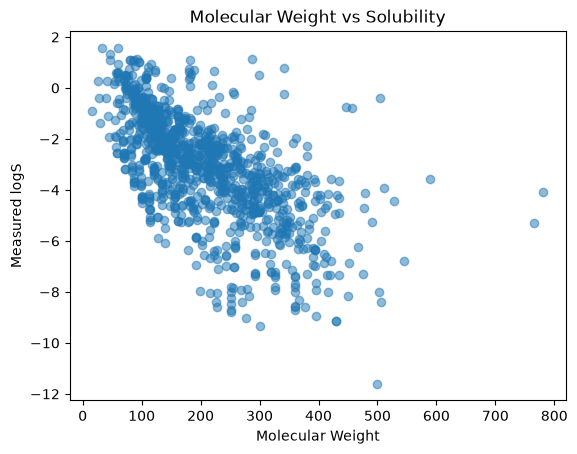

In [5]:
plt.scatter(
    df["Molecular Weight"],
    df[target],
    alpha=0.5
)

plt.xlabel("Molecular Weight")
plt.ylabel("Measured logS")
plt.title("Molecular Weight vs Solubility")
plt.show()

计算 分子量（Molecular Weight） 和 实测对数溶解度 之间的相关系数。

In [6]:
corr = df["Molecular Weight"].corr(
    df["measured log solubility in mols per litre"]
)

print(corr)

-0.6401894305424647


然后看 Polar Surface Area和溶解度的关系

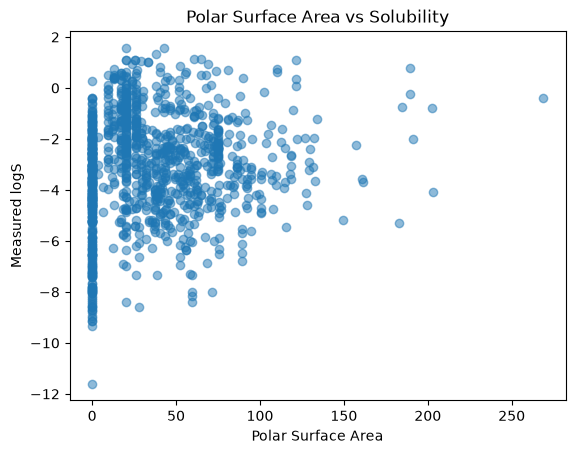

In [7]:
plt.scatter(
    df["Polar Surface Area"],
    df[target],
    alpha=0.5
)

plt.xlabel("Polar Surface Area")
plt.ylabel("Measured logS")
plt.title("Polar Surface Area vs Solubility")
plt.show()

先算这几个描述符和 measured logS 的 Pearson 相关系数

In [8]:
target = "measured log solubility in mols per litre"

features = [
    "Molecular Weight",
    "Polar Surface Area",
    "Number of H-Bond Donors",
    "Number of Rings",
    "Number of Rotatable Bonds"
]

for feature in features:
    corr = df[feature].corr(df[target])
    print(f"{feature}: {corr:.3f}")

Molecular Weight: -0.640
Polar Surface Area: 0.123
Number of H-Bond Donors: 0.209
Number of Rings: -0.512
Number of Rotatable Bonds: -0.244


计算并输出相关系数矩阵

In [9]:
selected = features + [target]

corr_matrix = df[selected].corr()

print(corr_matrix)

                                           Molecular Weight  \
Molecular Weight                                   1.000000   
Polar Surface Area                                 0.475440   
Number of H-Bond Donors                            0.254877   
Number of Rings                                    0.652521   
Number of Rotatable Bonds                          0.396894   
measured log solubility in mols per litre         -0.640189   

                                           Polar Surface Area  \
Molecular Weight                                     0.475440   
Polar Surface Area                                   1.000000   
Number of H-Bond Donors                              0.755932   
Number of Rings                                      0.308606   
Number of Rotatable Bonds                            0.286723   
measured log solubility in mols per litre            0.123210   

                                           Number of H-Bond Donors  \
Molecular Weight                

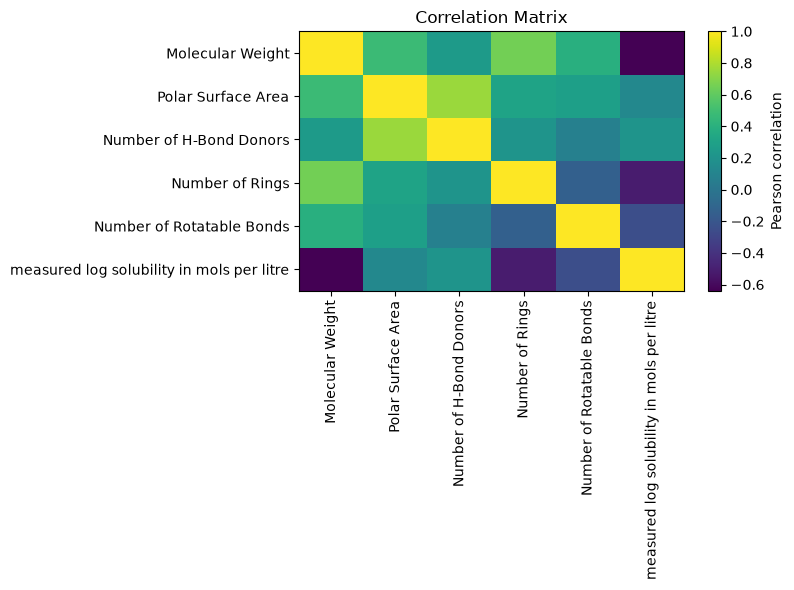

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.imshow(corr_matrix, aspect="auto")
plt.colorbar(label="Pearson correlation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.index)),
    corr_matrix.index
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

把 measured logS 和 ESOL 已经给出的 predicted logS 进行比较

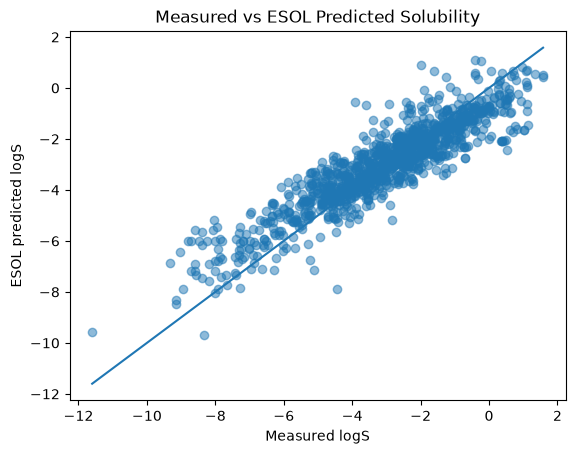

In [11]:
predicted = "ESOL predicted log solubility in mols per litre"


min_val = min(df[target].min(), df[predicted].min())
max_val = max(df[target].max(), df[predicted].max())

plt.scatter(
    df[target],
    df[predicted],
    alpha=0.5
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val]
)

plt.xlabel("Measured logS")
plt.ylabel("ESOL predicted logS")
plt.title("Measured vs ESOL Predicted Solubility")

plt.show()

找出模型预测溶解度与实际测量值差异最大的样本

In [12]:
df["error"] = (
    df["ESOL predicted log solubility in mols per litre"]
    - df["measured log solubility in mols per litre"]
)

df["abs_error"] = df["error"].abs()

df.sort_values("abs_error", ascending=False).head(10)

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles,error,abs_error
939,bromadiolone,-7.877,1,527.414,2,5,6,70.67,-4.445,OC(CC(c1ccccc1)c3c(O)c2ccccc2oc3=O)c4ccc(cc4)c...,-3.432,3.432
852,uric acid,-0.541,1,168.112,4,2,0,114.37,-3.930,O=c2[nH]c(=O)c1[nH]c(=O)[nH]c1[nH]2,3.389,3.389
819,Napthacene,-5.568,2,228.294,0,4,0,0.00,-8.600,c1ccc2cc3cc4ccccc4cc3cc2c1,3.032,3.032
292,Dimecron,-2.426,1,299.691,0,0,8,65.07,0.523,CCN(CC)C(=O)C(=CCOP(=O)(OC)OC)Cl,-2.949,2.949
918,guanine,-0.670,1,151.129,3,2,0,100.45,-3.583,Nc2nc1[nH]cnc1c(=O)[nH]2,2.913,2.913
733,alloxantin,0.919,1,286.156,6,2,1,191.00,-1.990,C1(=O)NC(=O)NC(=O)C1(O)C2(O)C(=O)NC(=O)NC2(=O),2.909,2.909
845,Benzo(b)fluorene,-5.189,2,216.283,0,4,0,0.00,-8.040,C1c2ccccc2c3cc4ccccc4cc13,2.851,2.851
220,Perylene,-6.007,2,252.316,0,5,0,0.00,-8.804,c1cc2cccc3c4cccc5cccc(c(c1)c23)c54,2.797,2.797
788,1-Octadecanol,-5.649,1,270.501,1,0,16,20.23,-8.400,CCCCCCCCCCCCCCCCCCO,2.751,2.751
637,Benzo(a)pyrene,-6.007,2,252.316,0,5,0,0.00,-8.699,c1ccc2c(c1)cc3ccc4cccc5ccc2c3c45,2.692,2.692


根据 SMILES 分子字符串计算 RDKit 分子描述符

In [13]:
from rdkit import Chem
from rdkit.Chem import Descriptors

def calculate_descriptors(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return {
            "MW_rdkit": None,
            "logP_rdkit": None,
            "TPSA_rdkit": None,
            "HBD_rdkit": None,
            "HBA_rdkit": None
        }

    return {
        "MW_rdkit": Descriptors.MolWt(mol),
        "logP_rdkit": Descriptors.MolLogP(mol),
        "TPSA_rdkit": Descriptors.TPSA(mol),
        "HBD_rdkit": Descriptors.NumHDonors(mol),
        "HBA_rdkit": Descriptors.NumHAcceptors(mol)
    }

In [14]:
first_smiles = df.loc[0, "smiles"]

print(first_smiles)

result = calculate_descriptors(first_smiles)

print(result)

OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 
{'MW_rdkit': 457.4320000000001, 'logP_rdkit': -3.1080199999999985, 'TPSA_rdkit': 202.31999999999996, 'HBD_rdkit': 7, 'HBA_rdkit': 12}


In [15]:
descriptor_df = df["smiles"].apply(calculate_descriptors).apply(pd.Series)

descriptor_df.head()

,MW_rdkit,logP_rdkit,TPSA_rdkit,HBD_rdkit,HBA_rdkit
0,457.432,-3.10802,202.32,7.0,12.0
1,201.225,2.84032,42.24,1.0,2.0
2,152.237,2.87800,17.07,0.0,1.0
3,278.354,6.29940,0.00,0.0,0.0
4,84.143,1.74810,0.00,0.0,1.0


In [16]:
df_rdkit = pd.concat([df, descriptor_df], axis=1)

df_rdkit.head()

,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles,error,abs_error,MW_rdkit,logP_rdkit,TPSA_rdkit,HBD_rdkit,HBA_rdkit
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.204,0.204,457.432,-3.10802,202.32,7.0,12.0
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2,0.415,0.415,201.225,2.84032,42.24,1.0,2.0
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O),-0.519,0.519,152.237,2.87800,17.07,0.0,1.0
3,Picene,-6.618,2,278.354,0,5,0,0.00,-7.87,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,1.252,1.252,278.354,6.29940,0.00,0.0,0.0
4,Thiophene,-2.232,2,84.143,0,1,0,0.00,-1.33,c1ccsc1,-0.902,0.902,84.143,1.74810,0.00,0.0,1.0


构造特征和目标

In [17]:
features = [
    "MW_rdkit",
    "logP_rdkit",
    "TPSA_rdkit",
    "HBD_rdkit",
    "HBA_rdkit"
]

target = "measured log solubility in mols per litre"

X = df_rdkit[features]
y = df_rdkit[target]

print(X.head())
print(y.head())

   MW_rdkit  logP_rdkit  TPSA_rdkit  HBD_rdkit  HBA_rdkit
0   457.432    -3.10802      202.32        7.0       12.0
1   201.225     2.84032       42.24        1.0        2.0
2   152.237     2.87800       17.07        0.0        1.0
3   278.354     6.29940        0.00        0.0        0.0
4    84.143     1.74810        0.00        0.0        1.0
0   -0.77
1   -3.30
2   -2.06
3   -7.87
4   -1.33
Name: measured log solubility in mols per litre, dtype: float64


划分训练集和测试集

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [19]:
print(X_train.shape)
print(X_test.shape)

(902, 5)
(226, 5)


In [20]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [21]:
y_pred = model.predict(X_test)

In [22]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)

rmse = mean_squared_error(
    y_test,
    y_pred
) ** 0.5

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 0.5862783385544722
RMSE: 0.8427553448775146
R2: 0.8497427335620393


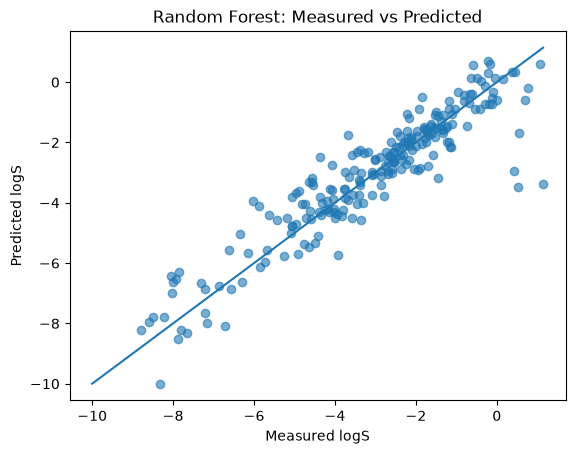

In [23]:
import matplotlib.pyplot as plt

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val]
)

plt.xlabel("Measured logS")
plt.ylabel("Predicted logS")
plt.title("Random Forest: Measured vs Predicted")

plt.show()

In [24]:
y_train_pred = model.predict(X_train)

train_r2 = r2_score(
    y_train,
    y_train_pred
)

test_r2 = r2_score(
    y_test,
    y_pred
)

print("Train R2:", train_r2)
print("Test R2:", test_r2)

Train R2: 0.9818748441193409
Test R2: 0.8497427335620393


In [25]:
import pandas as pd

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(importance_df)

      Feature  Importance
1  logP_rdkit    0.825185
0    MW_rdkit    0.106375
2  TPSA_rdkit    0.048542
4   HBA_rdkit    0.011973
3   HBD_rdkit    0.007925


用 Linear Regression 预测

In [26]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

In [27]:
linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

linear_rmse = mean_squared_error(
    y_test,
    linear_pred
) ** 0.5

linear_r2 = r2_score(
    y_test,
    linear_pred
)

print("Linear Regression")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R2:", linear_r2)

Linear Regression
MAE: 0.8376951730670886
RMSE: 1.10515927127473
R2: 0.7416061366627195


线性模型的系数

In [28]:
for feature, coef in zip(
    features,
    linear_model.coef_
):
    print(f"{feature}: {coef:.4f}")

MW_rdkit: -0.0042
logP_rdkit: -0.9279
TPSA_rdkit: -0.0156
HBD_rdkit: -0.0870
HBA_rdkit: 0.1698


 Random Forest 的 residual（残差）

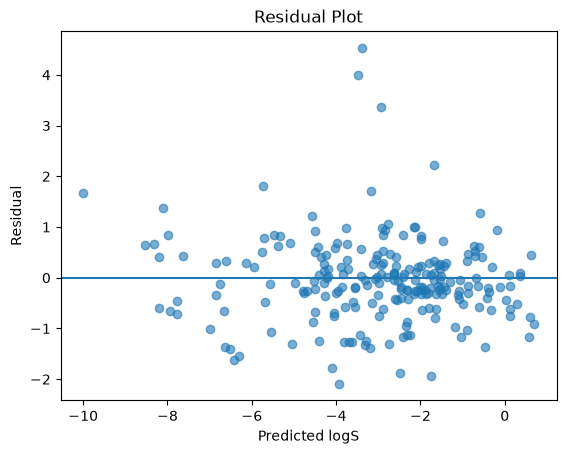

In [29]:
residuals = y_test - y_pred

plt.scatter(
    y_pred,
    residuals,
    alpha=0.6
)

plt.axhline(0)

plt.xlabel("Predicted logS")
plt.ylabel("Residual")
plt.title("Residual Plot")

plt.show()

在测试集上制作“真实值 vs 预测值”的误差分析表，并按误差最大的样本排序

In [30]:
results = X_test.copy()

results["Measured_logS"] = y_test
results["Predicted_logS"] = y_pred

results["Residual"] = (
    results["Measured_logS"]
    - results["Predicted_logS"]
)

results["Absolute_Error"] = results["Residual"].abs()

results = results.sort_values(
    "Absolute_Error",
    ascending=False
)

results.head(10)

,MW_rdkit,logP_rdkit,TPSA_rdkit,HBD_rdkit,HBA_rdkit,Measured_logS,Predicted_logS,Residual,Absolute_Error
1064,287.343,1.98820,64.63,1.0,6.0,1.144,-3.391713,4.535713,4.535713
292,299.691,2.39500,65.07,0.0,5.0,0.523,-3.482250,4.005250,4.005250
796,182.156,2.20400,44.76,0.0,4.0,0.430,-2.941007,3.371007,3.371007
758,183.169,1.24000,55.40,1.0,4.0,0.540,-1.678571,2.218571,2.218571
963,310.687,3.58010,58.20,2.0,2.0,-6.020,-3.930880,-2.089120,2.089120
588,376.369,-1.72356,161.56,5.0,8.0,-3.685,-1.740557,-1.944443,1.944443
643,132.206,2.56540,0.00,0.0,0.0,-4.370,-2.496640,-1.873360,1.873360
922,511.581,4.28940,92.18,2.0,5.0,-3.931,-5.732743,1.801743,1.801743
76,380.444,3.56300,75.71,1.0,4.0,-5.886,-4.102173,-1.783827,1.783827
884,198.134,1.51702,106.51,1.0,5.0,-1.456,-3.170243,1.714243,1.714243


In [31]:
results["Compound ID"] = df_rdkit.loc[
    results.index,
    "Compound ID"
]

results["smiles"] = df_rdkit.loc[
    results.index,
    "smiles"
]

results[
    [
        "Compound ID",
        "smiles",
        "Measured_logS",
        "Predicted_logS",
        "Absolute_Error"
    ]
].head(10)

,Compound ID,smiles,Measured_logS,Predicted_logS,Absolute_Error
1064,vamidothion,CNC(=O)C(C)SCCSP(=O)(OC)(OC),1.144,-3.391713,4.535713
292,Dimecron,CCN(CC)C(=O)C(=CCOP(=O)(OC)OC)Cl,0.523,-3.482250,4.005250
796,Triethyl phosphate,CCOP(=O)(OCC)OCC,0.430,-2.941007,3.371007
758,Acephate,COP(=O)(NC(C)=O)SC,0.540,-1.678571,2.218571
963,difluron,Fc1cccc(F)c1C(=O)NC(=O)Nc2ccc(Cl)cc2,-6.020,-3.930880,2.089120
588,Riboflavin,Cc3cc2nc1c(=O)[nH]c(=O)nc1n(CC(O)C(O)C(O)CO)c2...,-3.685,-1.740557,1.944443
643,"1,2,3,4-Tetrahydronapthalene",C1CCc2ccccc2C1,-4.370,-2.496640,1.873360
922,norbormide,OC(C1=CC2C5C(C1C2=C(c3ccccc3)c4ccccn4)C(=O)NC5...,-3.931,-5.732743,1.801743
76,3-Hexanoyloxymethylphenyltoin,O=C1N(COC(=O)CCCCC)C(=O)C(N1)(c2ccccc2)c3ccccc3,-5.886,-4.102173,1.783827
884,DNOC,Cc1cc(cc(N(=O)=O)c1O)N(=O)=O,-1.456,-3.170243,1.714243


K-fold cross-validation，中文通常叫“K 折交叉验证”，是一种用来评估机器学习模型是否稳定、是否具有泛化能力的方法。

In [32]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

cv_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

cv_scores = cross_val_score(
    cv_model,
    X,
    y,
    cv=5,
    scoring="r2"
)

print("R2 scores:", cv_scores)
print("Mean R2:", cv_scores.mean())
print("Std R2:", cv_scores.std())

R2 scores: [0.91360572 0.88753056 0.88579403 0.86065629 0.83130403]
Mean R2: 0.8757781250628799
Std R2: 0.027842342844374774


Shuffled K-fold “先把数据随机打乱，再做 K 折交叉验证”

In [33]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor

cv_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    cv_model,
    X,
    y,
    cv=kf,
    scoring="r2"
)

print("R2 scores:", cv_scores)
print("Mean R2:", cv_scores.mean())
print("Std R2:", cv_scores.std())

R2 scores: [0.84978718 0.89773849 0.8860682  0.86312536 0.88185512]
Mean R2: 0.8757148679439869
Std R2: 0.017091956587747387


用 RDKit 提取 Bemis–Murcko scaffold。
先拿一个分子试试看：

In [34]:
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

smiles = "CCOc1ccc(CC(=O)O)cc1"

mol = Chem.MolFromSmiles(smiles)

scaffold = MurckoScaffold.MurckoScaffoldSmiles(
    mol=mol
)

print("Molecule:", smiles)
print("Scaffold:", scaffold)

Molecule: CCOc1ccc(CC(=O)O)cc1
Scaffold: c1ccccc1


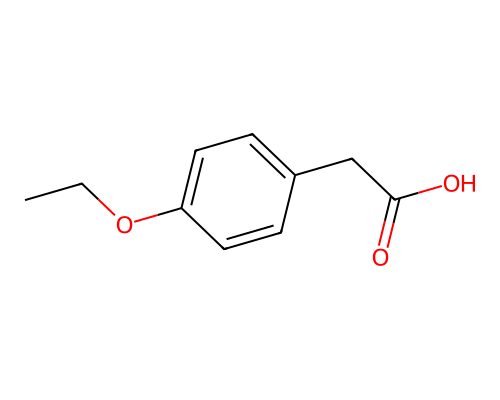

In [35]:
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

smiles = "CCOc1ccc(CC(=O)O)cc1"
mol = Chem.MolFromSmiles(smiles)

if mol is None:
    print("SMILES 无法解析")
else:
    display(Draw.MolToImage(mol, size=(500, 400)))

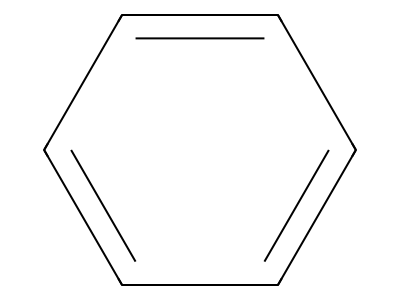

In [36]:
scaffold_mol = Chem.MolFromSmiles("c1ccccc1")
display(Draw.MolToImage(scaffold_mol, size=(400, 300)))

接着对 1128 个分子全部计算 scaffold：

In [37]:
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_scaffold(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    return MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol
    )

df_rdkit["scaffold"] = df_rdkit["smiles"].apply(
    get_scaffold
)

In [38]:
df_rdkit[
    ["Compound ID", "smiles", "scaffold"]
].head(10)

,Compound ID,smiles,scaffold
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,c1ccc(COC2CCCC(COC3CCCCO3)O2)cc1
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,O=C(Nc1ccccc1)c1ccoc1
2,citral,CC(C)=CCCC(C)=CC(=O),
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21
4,Thiophene,c1ccsc1,c1ccsc1
5,benzothiazole,c2ccc1scnc1c2,c1ccc2scnc2c1
6,"2,2,4,6,6'-PCB",Clc1cc(Cl)c(c(Cl)c1)c2c(Cl)cccc2Cl,c1ccc(-c2ccccc2)cc1
7,Estradiol,CC12CCC3C(CCc4cc(O)ccc34)C2CCC1O,c1ccc2c(c1)CCC1C2CCC2CCCC21
8,Dieldrin,ClC4=C(Cl)C5(Cl)C3C1CC(C2OC12)C3C4(Cl)C5(Cl)Cl,C1=CC2CC1C1C3CC(C4OC34)C21
9,Rotenone,COc5cc4OCC3Oc2c1CC(Oc1ccc2C(=O)C3c4cc5OC)C(C)=C,O=C1c2ccc3c(c2OC2COc4ccccc4C12)CCO3


In [39]:
print(
    "Number of molecules:",
    len(df_rdkit)
)

print(
    "Number of unique scaffolds:",
    df_rdkit["scaffold"].nunique()
)

Number of molecules: 1128
Number of unique scaffolds: 269


按照 scaffold 分组：

In [40]:
scaffold_groups = {}

for idx, scaffold in enumerate(
    df_rdkit["scaffold"]
):
    scaffold_groups.setdefault(
        scaffold,
        []
    ).append(idx)

然后按照 group 大小排序：

In [41]:
scaffold_sets = sorted(
    scaffold_groups.values(),
    key=len,
    reverse=True
)

接着做一个简单的：
80%  train
20%  test
scaffold split：

In [42]:
train_indices = []
test_indices = []

train_cutoff = int(
    0.8 * len(df_rdkit)
)

for group in scaffold_sets:

    if len(train_indices) + len(group) <= train_cutoff:
        train_indices.extend(group)

    else:
        test_indices.extend(group)

In [43]:
X_scaffold_train = X.iloc[train_indices]
X_scaffold_test = X.iloc[test_indices]

y_scaffold_train = y.iloc[train_indices]
y_scaffold_test = y.iloc[test_indices]

print("Train:", X_scaffold_train.shape)
print("Test:", X_scaffold_test.shape)

Train: (902, 5)
Test: (226, 5)


In [44]:
scaffold_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

scaffold_model.fit(
    X_scaffold_train,
    y_scaffold_train
)

scaffold_pred = scaffold_model.predict(
    X_scaffold_test
)

In [45]:
scaffold_mae = mean_absolute_error(
    y_scaffold_test,
    scaffold_pred
)

scaffold_rmse = mean_squared_error(
    y_scaffold_test,
    scaffold_pred
) ** 0.5

scaffold_r2 = r2_score(
    y_scaffold_test,
    scaffold_pred
)

print("Scaffold Split")
print("MAE:", scaffold_mae)
print("RMSE:", scaffold_rmse)
print("R2:", scaffold_r2)

Scaffold Split
MAE: 0.7772573704365934
RMSE: 1.033844191389619
R2: 0.7422462357502088


Morgan fingerprint + Random Forest

In [46]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
import numpy as np

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=2048
)

def smiles_to_fingerprint(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    fp = morgan_generator.GetFingerprint(mol)

    return np.array(fp)

In [47]:
fingerprints = np.array([
    smiles_to_fingerprint(smiles)
    for smiles in df_rdkit["smiles"]
])

print(fingerprints.shape)

(1128, 2048)


In [48]:
X_fp = fingerprints

y_fp = df_rdkit[
    "measured log solubility in mols per litre"
].values

print("X shape:", X_fp.shape)
print("y shape:", y_fp.shape)

X shape: (1128, 2048)
y shape: (1128,)


In [49]:
from sklearn.model_selection import train_test_split

X_fp_train, X_fp_test, y_fp_train, y_fp_test = train_test_split(
    X_fp,
    y_fp,
    test_size=0.2,
    random_state=42
)

print(X_fp_train.shape)
print(X_fp_test.shape)

(902, 2048)
(226, 2048)


In [50]:
from sklearn.ensemble import RandomForestRegressor

fp_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

fp_model.fit(
    X_fp_train,
    y_fp_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [51]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

fp_pred = fp_model.predict(X_fp_test)

fp_mae = mean_absolute_error(
    y_fp_test,
    fp_pred
)

fp_rmse = mean_squared_error(
    y_fp_test,
    fp_pred
) ** 0.5

fp_r2 = r2_score(
    y_fp_test,
    fp_pred
)

print("Morgan Fingerprint + Random Forest")
print("MAE:", fp_mae)
print("RMSE:", fp_rmse)
print("R2:", fp_r2)

Morgan Fingerprint + Random Forest
MAE: 0.8754978244405541
RMSE: 1.161034237232543
R2: 0.7148177403557211


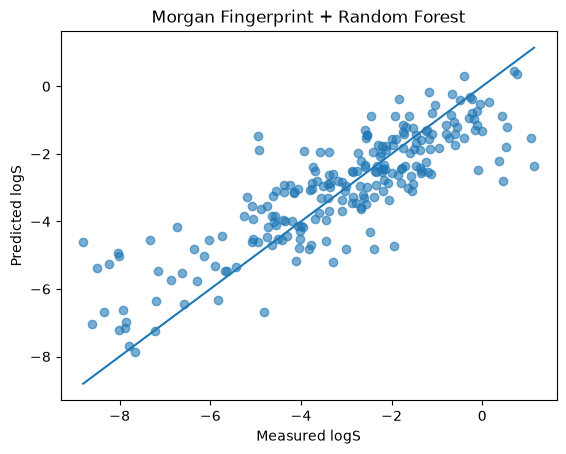

In [52]:
import matplotlib.pyplot as plt

plt.scatter(
    y_fp_test,
    fp_pred,
    alpha=0.6
)

min_val = min(
    y_fp_test.min(),
    fp_pred.min()
)

max_val = max(
    y_fp_test.max(),
    fp_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val]
)

plt.xlabel("Measured logS")
plt.ylabel("Predicted logS")
plt.title("Morgan Fingerprint + Random Forest")

plt.show()

In [53]:
X_fp_scaffold_train = X_fp[train_indices]
X_fp_scaffold_test = X_fp[test_indices]

y_fp_scaffold_train = y_fp[train_indices]
y_fp_scaffold_test = y_fp[test_indices]

print(
    "Train:",
    X_fp_scaffold_train.shape
)

print(
    "Test:",
    X_fp_scaffold_test.shape
)

Train: (902, 2048)
Test: (226, 2048)


In [54]:
fp_scaffold_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

fp_scaffold_model.fit(
    X_fp_scaffold_train,
    y_fp_scaffold_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [55]:
fp_scaffold_pred = fp_scaffold_model.predict(
    X_fp_scaffold_test
)

In [56]:
fp_scaffold_mae = mean_absolute_error(
    y_fp_scaffold_test,
    fp_scaffold_pred
)

fp_scaffold_rmse = mean_squared_error(
    y_fp_scaffold_test,
    fp_scaffold_pred
) ** 0.5

fp_scaffold_r2 = r2_score(
    y_fp_scaffold_test,
    fp_scaffold_pred
)

print("Morgan Fingerprint - Scaffold Split")
print("MAE:", fp_scaffold_mae)
print("RMSE:", fp_scaffold_rmse)
print("R2:", fp_scaffold_r2)

Morgan Fingerprint - Scaffold Split
MAE: 1.2909424814931874
RMSE: 1.68049935561373
R2: 0.3189617052507132


scaffold split检查

In [57]:
print("Train molecules:", len(train_indices))
print("Test molecules:", len(test_indices))

print(
    "Train fraction:",
    len(train_indices) / len(df_rdkit)
)

print(
    "Test fraction:",
    len(test_indices) / len(df_rdkit)
)

Train molecules: 902
Test molecules: 226
Train fraction: 0.799645390070922
Test fraction: 0.20035460992907803


In [58]:
scaffold_sizes = sorted(
    [len(group) for group in scaffold_sets],
    reverse=True
)

print("Largest scaffold groups:")
print(scaffold_sizes[:20])

Largest scaffold groups:
[317, 254, 39, 22, 21, 17, 16, 14, 12, 10, 9, 9, 8, 7, 7, 6, 6, 6, 6, 5]


In [59]:
print(
    "Empty scaffold molecules:",
    (df_rdkit["scaffold"] == "").sum()
)

Empty scaffold molecules: 317


In [60]:
descriptor_features = [
    "MW_rdkit",
    "logP_rdkit",
    "TPSA_rdkit",
    "HBD_rdkit",
    "HBA_rdkit"
]

X_desc = df_rdkit[
    descriptor_features
].values

In [61]:
import numpy as np

X_combined = np.hstack([
    X_desc,
    fingerprints
])

print(X_combined.shape)

(1128, 2053)


In [62]:
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(
    X_combined,
    y_fp,
    test_size=0.2,
    random_state=42
)

combined_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

combined_model.fit(
    X_c_train,
    y_c_train
)

combined_pred = combined_model.predict(
    X_c_test
)

In [63]:
combined_mae = mean_absolute_error(
    y_c_test,
    combined_pred
)

combined_rmse = mean_squared_error(
    y_c_test,
    combined_pred
) ** 0.5

combined_r2 = r2_score(
    y_c_test,
    combined_pred
)

print("Descriptors + Morgan FP")
print("MAE:", combined_mae)
print("RMSE:", combined_rmse)
print("R2:", combined_r2)

Descriptors + Morgan FP
MAE: 0.5490483629723277
RMSE: 0.7958605068949789
R2: 0.8659995178889963


In [64]:
X_c_scaffold_train = X_combined[train_indices]
X_c_scaffold_test = X_combined[test_indices]

y_c_scaffold_train = y_fp[train_indices]
y_c_scaffold_test = y_fp[test_indices]

combined_scaffold_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

combined_scaffold_model.fit(
    X_c_scaffold_train,
    y_c_scaffold_train
)

combined_scaffold_pred = combined_scaffold_model.predict(
    X_c_scaffold_test
)

print("Combined - Scaffold Split")

print(
    "MAE:",
    mean_absolute_error(
        y_c_scaffold_test,
        combined_scaffold_pred
    )
)

print(
    "RMSE:",
    mean_squared_error(
        y_c_scaffold_test,
        combined_scaffold_pred
    ) ** 0.5
)

print(
    "R2:",
    r2_score(
        y_c_scaffold_test,
        combined_scaffold_pred
    )
)

Combined - Scaffold Split
MAE: 0.7060904781570444
RMSE: 0.951203528299801
R2: 0.7818065358174104


有环分子继续按照 Bemis–Murcko scaffold 分组；无环分子不再全部塞进 ""，而是给它们单独的 group

In [65]:
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold

def get_scaffold_group(smiles, idx):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return f"INVALID_{idx}"

    scaffold = MurckoScaffold.MurckoScaffoldSmiles(
        mol=mol
    )

    # 无环分子的 Murcko scaffold 是空字符串
    if scaffold == "":
        return f"ACYCLIC_{idx}"

    return scaffold

In [66]:
df_rdkit["scaffold_group"] = [
    get_scaffold_group(smiles, idx)
    for idx, smiles in enumerate(df_rdkit["smiles"])
]

In [67]:
print(
    "Unique scaffold groups:",
    df_rdkit["scaffold_group"].nunique()
)

print(
    df_rdkit[
        ["Compound ID", "scaffold", "scaffold_group"]
    ].head(20)
)

Unique scaffold groups: 585
           Compound ID                             scaffold  \
0            Amigdalin     c1ccc(COC2CCCC(COC3CCCCO3)O2)cc1   
1             Fenfuram                O=C(Nc1ccccc1)c1ccoc1   
2               citral                                        
3               Picene   c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21   
4            Thiophene                              c1ccsc1   
5        benzothiazole                        c1ccc2scnc2c1   
6       2,2,4,6,6'-PCB                  c1ccc(-c2ccccc2)cc1   
7            Estradiol          c1ccc2c(c1)CCC1C2CCC2CCCC21   
8             Dieldrin           C1=CC2CC1C1C3CC(C4OC34)C21   
9             Rotenone  O=C1c2ccc3c(c2OC2COc4ccccc4C12)CCO3   
10       2-pyrrolidone                            O=C1CCCN1   
11  2-Chloronapthalene                       c1ccc2ccccc2c1   
12          1-Pentene                                         
13           Primidone               O=C1NCNC(=O)C1c1ccccc1   
14         Tetradecane     

In [68]:
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor

groups = df_rdkit["scaffold_group"].values

group_kfold = GroupKFold(
    n_splits=5
)

group_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

group_scores = cross_val_score(
    group_model,
    X_combined,
    y_fp,
    groups=groups,
    cv=group_kfold,
    scoring="r2"
)

print("GroupKFold R2 scores:")
print(group_scores)

print("Mean R2:", group_scores.mean())
print("Std R2:", group_scores.std())

GroupKFold R2 scores:
[0.73273278 0.88521465 0.88869242 0.84592936 0.86643596]
Mean R2: 0.8438010352600556
Std R2: 0.0575905399116148


第二阶段：GNN（Graph Neural Network）

In [69]:
from rdkit import Chem

smiles = "CCO"
mol = Chem.MolFromSmiles(smiles)

for atom in mol.GetAtoms():
    print(
        "Atom index:", atom.GetIdx(),
        "Element:", atom.GetSymbol(),
        "Atomic number:", atom.GetAtomicNum(),
        "Degree:", atom.GetDegree(),
        "Aromatic:", atom.GetIsAromatic()
    )

Atom index: 0 Element: C Atomic number: 6 Degree: 1 Aromatic: False
Atom index: 1 Element: C Atomic number: 6 Degree: 2 Aromatic: False
Atom index: 2 Element: O Atomic number: 8 Degree: 1 Aromatic: False


In [70]:
for bond in mol.GetBonds():
    print(
        "Start:", bond.GetBeginAtomIdx(),
        "End:", bond.GetEndAtomIdx(),
        "Bond type:", bond.GetBondType()
    )

Start: 0 End: 1 Bond type: SINGLE
Start: 1 End: 2 Bond type: SINGLE


In [71]:
import numpy as np
from rdkit import Chem

smiles = "CCO"
mol = Chem.MolFromSmiles(smiles)

node_features = []

for atom in mol.GetAtoms():
    features = [
        atom.GetAtomicNum(),
        atom.GetDegree(),
        int(atom.GetIsAromatic())
    ]

    node_features.append(features)

X = np.array(node_features)

print(X)
print("Shape:", X.shape)

[[6 1 0]
 [6 2 0]
 [8 1 0]]
Shape: (3, 3)


In [72]:
edges = []

for bond in mol.GetBonds():
    i = bond.GetBeginAtomIdx()
    j = bond.GetEndAtomIdx()

    edges.append([i, j])
    edges.append([j, i])

edge_index = np.array(edges).T

print(edge_index)
print("Shape:", edge_index.shape)

[[0 1 1 2]
 [1 0 2 1]]
Shape: (2, 4)


In [73]:
edge_features = []

for bond in mol.GetBonds():
    bond_type = bond.GetBondTypeAsDouble()

    edge_features.append([bond_type])
    edge_features.append([bond_type])

edge_attr = np.array(edge_features)

print(edge_attr)
print("Shape:", edge_attr.shape)

[[1.]
 [1.]
 [1.]
 [1.]]
Shape: (4, 1)


In [74]:
def one_hot(value, choices):
    return [
        1 if value == choice else 0
        for choice in choices
    ]

In [75]:
atom_types = ["C", "N", "O", "F"]

print(one_hot("C", atom_types))
print(one_hot("O", atom_types))

[1, 0, 0, 0]
[0, 0, 1, 0]


In [76]:
from rdkit import Chem
import numpy as np

atom_types = [
    "C", "N", "O", "F", "P",
    "S", "Cl", "Br", "I", "Other"
]

bond_types = [
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.DOUBLE,
    Chem.rdchem.BondType.TRIPLE,
    Chem.rdchem.BondType.AROMATIC
]

In [77]:
def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # 1. 构建节点特征
    node_features = []

    for atom in mol.GetAtoms():
        symbol = atom.GetSymbol()

        if symbol not in atom_types:
            symbol = "Other"

        node_features.append(
            one_hot(symbol, atom_types)
        )

    x = np.array(
        node_features,
        dtype=np.float32
    )

    # 2. 构建边及边特征
    edges = []
    edge_features = []

    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        edges.append([i, j])
        edges.append([j, i])

        bond_feature = one_hot(
            bond.GetBondType(),
            bond_types
        )

        edge_features.append(bond_feature)
        edge_features.append(bond_feature)

    # 3. 转换成 NumPy 数组
    edge_index = (
        np.array(edges, dtype=np.int64).T
        if edges else np.empty((2, 0), dtype=np.int64)
    )

    edge_attr = (
        np.array(edge_features, dtype=np.float32)
        if edge_features
        else np.empty((0, len(bond_types)), dtype=np.float32)
    )

    return {
        "x": x,
        "edge_index": edge_index,
        "edge_attr": edge_attr
    }

测试乙醇

In [78]:
graph = smiles_to_graph("CCO")

print("Node features:")
print(graph["x"])

print("Edge index:")
print(graph["edge_index"])

print("Edge attributes:")
print(graph["edge_attr"])

print("Shapes:")
print(graph["x"].shape)
print(graph["edge_index"].shape)
print(graph["edge_attr"].shape)

Node features:
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]]
Edge index:
[[0 1 1 2]
 [1 0 2 1]]
Edge attributes:
[[1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]]
Shapes:
(3, 10)
(2, 4)
(4, 4)


把 ESOL 的 1128 个分子转换为 Graph Dataset

In [79]:
graphs = [
    smiles_to_graph(smiles)
    for smiles in df_rdkit["smiles"]
]

print("Number of graphs:", len(graphs))

print(
    "Invalid graphs:",
    sum(g is None for g in graphs)
)

Number of graphs: 1128
Invalid graphs: 0


In [80]:
import numpy as np

graph = smiles_to_graph("CCO")

x = graph["x"]
edge_index = graph["edge_index"]

# 为每个原子准备一个全零向量
messages = np.zeros_like(x)

# 从相邻原子接收并汇总消息
for src, dst in edge_index.T:
    messages[dst] += x[src]

print("Original node features:")
print(x)

print("Aggregated messages:")
print(messages)

print("Shape:", messages.shape)

Original node features:
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]]
Aggregated messages:
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
Shape: (3, 10)


In [81]:
updated_x = np.concatenate(
    [x, messages],
    axis=1
)

print("Updated shape:", updated_x.shape)
print(updated_x)

Updated shape: (3, 20)
[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [84]:
import torch

graph = smiles_to_graph("CCO")

x = torch.tensor(
    graph["x"],
    dtype=torch.float32
)

edge_index = torch.tensor(
    graph["edge_index"],
    dtype=torch.long
)

print("Node features:", x.shape)
print("Edge index:", edge_index.shape)

Node features: torch.Size([3, 10])
Edge index: torch.Size([2, 4])


In [85]:
import torch.nn as nn

linear = nn.Linear(
    in_features=10,
    out_features=8
)

transformed_x = linear(x)

print(transformed_x.shape)

torch.Size([3, 8])


In [86]:
import torch
import torch.nn as nn

class SimpleGNN(nn.Module):

    def __init__(self, input_dim=10, hidden_dim=8):
        super().__init__()

        self.message_linear = nn.Linear(
            input_dim, hidden_dim
        )

        self.self_linear = nn.Linear(
            input_dim, hidden_dim
        )

        self.output_linear = nn.Linear(
            hidden_dim, 1
        )

    def forward(self, x, edge_index):

        src, dst = edge_index

        # 1. 学习每个原子要发送的消息
        messages = self.message_linear(x)

        # 2. 汇总邻居消息
        aggregated = torch.zeros_like(messages)

        aggregated.index_add_(
            0,
            dst,
            messages[src]
        )

        # 3. 结合自身与邻居信息
        h = torch.relu(
            self.self_linear(x) + aggregated
        )

        # 4. 输出每个原子的预测值
        return self.output_linear(h).squeeze(-1)

In [87]:
torch.manual_seed(42)

model = SimpleGNN(
    input_dim=10,
    hidden_dim=8
)

y = torch.tensor(
    [0.0, 1.0, 0.0]
)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

for epoch in range(201):

    optimizer.zero_grad()

    predictions = model(x, edge_index)

    loss = criterion(predictions, y)

    loss.backward()

    optimizer.step()

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}, "
            f"Loss: {loss.item():.6f}"
        )

Epoch 0, Loss: 0.216106
Epoch 50, Loss: 0.001323
Epoch 100, Loss: 0.000001
Epoch 150, Loss: 0.000000
Epoch 200, Loss: 0.000000


In [88]:
model.eval()

with torch.no_grad():
    predictions = model(x, edge_index)

print("Target:", y.numpy())
print("Prediction:", predictions.numpy())

Target: [0. 1. 0.]
Prediction: [-2.7909875e-05  1.0000086e+00  1.5281141e-05]


In [89]:
import torch
import torch.nn as nn

class MessagePassingLayer(nn.Module):

    def __init__(self, input_dim, hidden_dim):
        super().__init__()

        self.self_linear = nn.Linear(
            input_dim, hidden_dim
        )

        self.message_linear = nn.Linear(
            input_dim, hidden_dim
        )

    def forward(self, x, edge_index):

        src, dst = edge_index

        # 邻居发送可学习的消息
        messages = self.message_linear(x[src])

        # 汇总每个原子接收到的消息
        aggregated = torch.zeros(
            x.size(0),
            messages.size(1),
            device=x.device
        )

        aggregated.index_add_(
            0, dst, messages
        )

        # 更新原子特征
        h = torch.relu(
            self.self_linear(x) + aggregated
        )

        return h

In [90]:
class MolecularGNN(nn.Module):

    def __init__(self, input_dim=10, hidden_dim=32):
        super().__init__()

        # 第一层消息传递
        self.gnn1 = MessagePassingLayer(
            input_dim, hidden_dim
        )

        # 第二层消息传递
        self.gnn2 = MessagePassingLayer(
            hidden_dim, hidden_dim
        )

        # 分子性质回归层
        self.regressor = nn.Linear(
            hidden_dim, 1
        )

    def forward(self, x, edge_index):

        # 1. 第一层 Message Passing
        h = self.gnn1(x, edge_index)

        # 2. 第二层 Message Passing
        h = self.gnn2(h, edge_index)

        # 3. Graph Pooling
        molecule_embedding = h.sum(
            dim=0,
            keepdim=True
        )

        # 4. 预测整个分子的 logS
        prediction = self.regressor(
            molecule_embedding
        )

        return prediction.squeeze()

使用乙醇测试 MolecularGNN

In [91]:
graph = smiles_to_graph("CCO")

x = torch.tensor(
    graph["x"],
    dtype=torch.float32
)

edge_index = torch.tensor(
    graph["edge_index"],
    dtype=torch.long
)

model = MolecularGNN(
    input_dim=10,
    hidden_dim=32
)

model.eval()

with torch.no_grad():
    prediction = model(x, edge_index)

print("Prediction:", prediction.item())
print("Output shape:", prediction.shape)

Prediction: 0.12694214284420013
Output shape: torch.Size([])


In [92]:
# 第一条 ESOL 数据
first_smiles = df_rdkit.loc[0, "smiles"]

# 获得实验值
target = "measured log solubility in mols per litre"
measured_logS = df_rdkit.loc[0, target]

# 转换为分子图
graph = smiles_to_graph(first_smiles)

x = torch.tensor(
    graph["x"],
    dtype=torch.float32
)

edge_index = torch.tensor(
    graph["edge_index"],
    dtype=torch.long
)

# 进行前向传播
with torch.no_grad():
    predicted_logS = model(
        x, edge_index
    ).item()

print("SMILES:", first_smiles)
print("Measured logS:", measured_logS)
print("Predicted logS:", predicted_logS)

SMILES: OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)C(O)C3O 
Measured logS: -0.77
Predicted logS: 1.3766964673995972


准备 ESOL Graph Dataset

In [93]:
import numpy as np

target = "measured log solubility in mols per litre"

graphs = [
    smiles_to_graph(smiles)
    for smiles in df_rdkit["smiles"]
]

labels = df_rdkit[target].to_numpy(dtype=np.float32)

assert all(g is not None for g in graphs)

dataset = list(zip(graphs, labels))

print("Molecules:", len(dataset))
print("First label:", dataset[0][1])

Molecules: 1128
First label: -0.77


In [94]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.2,
    random_state=42
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 721
Validation: 181
Test: 226


In [95]:
import torch
from torch.utils.data import DataLoader, Subset

def collate_graphs(batch):

    xs = []
    edges = []
    batch_ids = []
    ys = []

    offset = 0

    for graph_id, (graph, label) in enumerate(batch):

        x = torch.tensor(
            graph["x"], dtype=torch.float32
        )

        edge_index = torch.tensor(
            graph["edge_index"], dtype=torch.long
        )

        xs.append(x)
        edges.append(edge_index + offset)

        batch_ids.append(
            torch.full(
                (x.size(0),),
                graph_id,
                dtype=torch.long
            )
        )

        ys.append(label)

        offset += x.size(0)

    return (
        torch.cat(xs, dim=0),
        torch.cat(edges, dim=1),
        torch.cat(batch_ids),
        torch.tensor(ys, dtype=torch.float32)
    )

In [96]:
train_loader = DataLoader(
    Subset(dataset, train_idx.tolist()),
    batch_size=32,
    shuffle=True,
    collate_fn=collate_graphs
)

val_loader = DataLoader(
    Subset(dataset, val_idx.tolist()),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_graphs
)

test_loader = DataLoader(
    Subset(dataset, test_idx.tolist()),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_graphs
)

In [97]:
import torch.nn as nn

class BatchMolecularGNN(nn.Module):

    def __init__(self, input_dim=10, hidden_dim=32):
        super().__init__()

        self.gnn1 = MessagePassingLayer(
            input_dim, hidden_dim
        )

        self.gnn2 = MessagePassingLayer(
            hidden_dim, hidden_dim
        )

        self.regressor = nn.Linear(
            hidden_dim, 1
        )

    def forward(self, x, edge_index, batch_ids):

        h = self.gnn1(x, edge_index)
        h = self.gnn2(h, edge_index)

        # 统计当前 batch 中有多少个分子
        num_graphs = int(batch_ids.max().item()) + 1

        # 为每个分子建立一个隐藏向量
        pooled = h.new_zeros(
            (num_graphs, h.size(1))
        )

        # 分别汇总每个分子的原子信息
        pooled.index_add_(0, batch_ids, h)

        # 每个分子输出一个 logS
        return self.regressor(pooled).squeeze(-1)

In [98]:
train_labels = labels[train_idx]

y_mean = float(train_labels.mean())
y_std = float(train_labels.std())

print("Training mean:", y_mean)
print("Training std:", y_std)

Training mean: -3.047827959060669
Training std: 2.1100542545318604


In [99]:
import copy

torch.manual_seed(42)

model = BatchMolecularGNN(
    input_dim=10,
    hidden_dim=32
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

criterion = nn.MSELoss()

best_val_loss = float("inf")
best_state = None
patience = 15
wait = 0

for epoch in range(1, 101):

    model.train()

    train_total = 0

    for x, edge_index, batch_ids, y in train_loader:

        optimizer.zero_grad()

        pred = model(x, edge_index, batch_ids)

        y_scaled = (y - y_mean) / y_std

        loss = criterion(pred, y_scaled)

        loss.backward()
        optimizer.step()

        train_total += loss.item() * len(y)

    train_loss = train_total / len(train_idx)

    # Validation
    model.eval()
    val_total = 0

    with torch.no_grad():

        for x, edge_index, batch_ids, y in val_loader:

            pred = model(x, edge_index, batch_ids)
            y_scaled = (y - y_mean) / y_std

            val_loss = criterion(pred, y_scaled)

            val_total += val_loss.item() * len(y)

    val_loss = val_total / len(val_idx)

    # 保存验证集上表现最好的模型
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    if epoch % 10 == 0 or epoch == 1:
        print(
            f"Epoch {epoch:3d} | "
            f"Train MSE: {train_loss:.4f} | "
            f"Val MSE: {val_loss:.4f}"
        )

    if wait >= patience:
        print("Early stopping at epoch", epoch)
        break

model.load_state_dict(best_state)

Epoch   1 | Train MSE: 7.6875 | Val MSE: 1.6377
Epoch  10 | Train MSE: 0.5266 | Val MSE: 0.4167
Epoch  20 | Train MSE: 0.3906 | Val MSE: 0.3204
Epoch  30 | Train MSE: 0.3450 | Val MSE: 0.3330
Epoch  40 | Train MSE: 0.3306 | Val MSE: 0.2625
Epoch  50 | Train MSE: 0.2761 | Val MSE: 0.2619
Epoch  60 | Train MSE: 0.2583 | Val MSE: 0.2281
Epoch  70 | Train MSE: 0.2448 | Val MSE: 0.2210
Epoch  80 | Train MSE: 0.2546 | Val MSE: 0.2063
Epoch  90 | Train MSE: 0.2266 | Val MSE: 0.2403
Epoch 100 | Train MSE: 0.2041 | Val MSE: 0.1946


<All keys matched successfully>

In [100]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for x, edge_index, batch_ids, y in test_loader:

        pred_scaled = model(
            x, edge_index, batch_ids
        )

        # 恢复到原始 logS 单位
        pred = pred_scaled * y_std + y_mean

        y_true.extend(y.numpy().tolist())
        y_pred.extend(pred.numpy().tolist())

mae = mean_absolute_error(y_true, y_pred)
rmse = mean_squared_error(y_true, y_pred) ** 0.5
r2 = r2_score(y_true, y_pred)

print("GNN Test Results")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

GNN Test Results
MAE: 0.7880996739310501
RMSE: 1.0402011569696248
R2: 0.771088757958791


编写新的 Message Passing Layer

In [101]:
import torch
import torch.nn as nn

class BondMessagePassingLayer(nn.Module):

    def __init__(self, node_dim, bond_dim, hidden_dim):
        super().__init__()

        self.self_linear = nn.Linear(
            node_dim, hidden_dim
        )

        self.message_linear = nn.Linear(
            node_dim + bond_dim,
            hidden_dim,
            bias=False
        )

    def forward(self, x, edge_index, edge_attr):

        src, dst = edge_index

        # 1. 拼接邻居原子特征与化学键特征
        edge_inputs = torch.cat(
            [x[src], edge_attr],
            dim=1
        )

        # 2. 生成可训练的消息
        messages = self.message_linear(edge_inputs)

        # 3. 汇总消息
        aggregated = x.new_zeros(
            (x.size(0), messages.size(1))
        )

        aggregated.index_add_(
            0, dst, messages
        )

        # 4. 更新节点表示
        h = torch.relu(
            self.self_linear(x) + aggregated
        )

        return h

In [102]:
class BondAwareGNN(nn.Module):

    def __init__(self, input_dim=10,
                 bond_dim=4, hidden_dim=32):
        super().__init__()

        self.gnn1 = BondMessagePassingLayer(
            input_dim, bond_dim, hidden_dim
        )

        self.gnn2 = BondMessagePassingLayer(
            hidden_dim, bond_dim, hidden_dim
        )

        self.regressor = nn.Linear(
            hidden_dim, 1
        )

    def forward(self, x, edge_index,
                edge_attr, batch_ids):

        h = self.gnn1(x, edge_index, edge_attr)

        h = self.gnn2(h, edge_index, edge_attr)

        num_graphs = int(batch_ids.max().item()) + 1

        pooled = h.new_zeros(
            (num_graphs, h.size(1))
        )

        pooled.index_add_(0, batch_ids, h)

        return self.regressor(pooled).squeeze(-1)

In [103]:
graph = smiles_to_graph("CCO")

x = torch.tensor(
    graph["x"], dtype=torch.float32
)

edge_index = torch.tensor(
    graph["edge_index"], dtype=torch.long
)

edge_attr = torch.tensor(
    graph["edge_attr"], dtype=torch.float32
)

batch_ids = torch.zeros(
    x.size(0), dtype=torch.long
)

torch.manual_seed(42)

model = BondAwareGNN(
    input_dim=10,
    bond_dim=4,
    hidden_dim=32
)

model.eval()

with torch.no_grad():
    prediction = model(
        x, edge_index, edge_attr, batch_ids
    )

print("Node shape:", x.shape)
print("Edge index shape:", edge_index.shape)
print("Edge attr shape:", edge_attr.shape)
print("Prediction shape:", prediction.shape)
print("Prediction:", prediction.item())

Node shape: torch.Size([3, 10])
Edge index shape: torch.Size([2, 4])
Edge attr shape: torch.Size([4, 4])
Prediction shape: torch.Size([1])
Prediction: -0.07923530042171478


In [104]:
import torch
from torch.utils.data import DataLoader, Subset

def collate_bond_graphs(batch):

    xs = []
    edges = []
    edge_attrs = []
    batch_ids = []
    ys = []

    offset = 0

    for graph_id, (graph, label) in enumerate(batch):

        x = torch.tensor(
            graph["x"], dtype=torch.float32
        )

        edge_index = torch.tensor(
            graph["edge_index"], dtype=torch.long
        )

        edge_attr = torch.tensor(
            graph["edge_attr"], dtype=torch.float32
        )

        xs.append(x)

        # 调整节点编号，防止不同分子的边互相连接
        edges.append(edge_index + offset)

        # 边特征按照原有边顺序拼接
        edge_attrs.append(edge_attr)

        batch_ids.append(
            torch.full(
                (x.size(0),),
                graph_id,
                dtype=torch.long
            )
        )

        ys.append(label)

        offset += x.size(0)

    return (
        torch.cat(xs, dim=0),
        torch.cat(edges, dim=1),
        torch.cat(edge_attrs, dim=0),
        torch.cat(batch_ids),
        torch.tensor(ys, dtype=torch.float32)
    )

In [105]:
train_loader_bond = DataLoader(
    Subset(dataset, train_idx.tolist()),
    batch_size=32,
    shuffle=True,
    collate_fn=collate_bond_graphs,
    generator=torch.Generator().manual_seed(42)
)

val_loader_bond = DataLoader(
    Subset(dataset, val_idx.tolist()),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_bond_graphs
)

test_loader_bond = DataLoader(
    Subset(dataset, test_idx.tolist()),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_bond_graphs
)

In [106]:
batch = next(iter(train_loader_bond))

x, edge_index, edge_attr, batch_ids, y = batch

print("Node features:", x.shape)
print("Edge index:", edge_index.shape)
print("Edge attributes:", edge_attr.shape)
print("Batch IDs:", batch_ids.shape)
print("Labels:", y.shape)

Node features: torch.Size([432, 10])
Edge index: torch.Size([2, 882])
Edge attributes: torch.Size([882, 4])
Batch IDs: torch.Size([432])
Labels: torch.Size([32])


In [107]:
import copy
import torch.nn as nn

torch.manual_seed(42)

bond_model = BondAwareGNN(
    input_dim=10,
    bond_dim=4,
    hidden_dim=32
)

optimizer = torch.optim.Adam(
    bond_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

criterion = nn.MSELoss()

# 标准化参数只从训练集计算
y_mean = float(labels[train_idx].mean())
y_std = float(labels[train_idx].std())

best_val_loss = float("inf")
best_state = None
patience = 15
wait = 0

for epoch in range(1, 101):

    bond_model.train()

    train_total = 0

    for x, edge_index, edge_attr, batch_ids, y in train_loader_bond:

        optimizer.zero_grad()

        pred = bond_model(
            x,
            edge_index,
            edge_attr,
            batch_ids
        )

        y_scaled = (y - y_mean) / y_std

        loss = criterion(pred, y_scaled)

        loss.backward()
        optimizer.step()

        train_total += loss.item() * len(y)

    train_loss = train_total / len(train_idx)

    # Validation
    bond_model.eval()
    val_total = 0

    with torch.no_grad():

        for x, edge_index, edge_attr, batch_ids, y in val_loader_bond:

            pred = bond_model(
                x,
                edge_index,
                edge_attr,
                batch_ids
            )

            y_scaled = (y - y_mean) / y_std

            val_loss = criterion(pred, y_scaled)

            val_total += val_loss.item() * len(y)

    val_loss = val_total / len(val_idx)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(
            bond_model.state_dict()
        )
        wait = 0
    else:
        wait += 1

    if epoch % 10 == 0 or epoch == 1:
        print(
            f"Epoch {epoch:3d} | "
            f"Train MSE: {train_loss:.4f} | "
            f"Val MSE: {val_loss:.4f}"
        )

    if wait >= patience:
        print("Early stopping at epoch", epoch)
        break

bond_model.load_state_dict(best_state)

Epoch   1 | Train MSE: 1.4147 | Val MSE: 0.7193
Epoch  10 | Train MSE: 0.5118 | Val MSE: 0.3738
Epoch  20 | Train MSE: 0.3724 | Val MSE: 0.3334
Epoch  30 | Train MSE: 0.3060 | Val MSE: 0.2527
Epoch  40 | Train MSE: 0.2416 | Val MSE: 0.2468
Epoch  50 | Train MSE: 0.2101 | Val MSE: 0.1972
Epoch  60 | Train MSE: 0.1824 | Val MSE: 0.1756
Epoch  70 | Train MSE: 0.2017 | Val MSE: 0.2434
Epoch  80 | Train MSE: 0.1672 | Val MSE: 0.1524
Epoch  90 | Train MSE: 0.1506 | Val MSE: 0.1502
Epoch 100 | Train MSE: 0.1390 | Val MSE: 0.1510


<All keys matched successfully>

In [108]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

bond_model.eval()

y_true = []
y_pred = []

with torch.no_grad():

    for x, edge_index, edge_attr, batch_ids, y in test_loader_bond:

        pred_scaled = bond_model(
            x,
            edge_index,
            edge_attr,
            batch_ids
        )

        pred = pred_scaled * y_std + y_mean

        y_true.extend(y.numpy().tolist())
        y_pred.extend(pred.numpy().tolist())

bond_mae = mean_absolute_error(y_true, y_pred)
bond_rmse = mean_squared_error(y_true, y_pred) ** 0.5
bond_r2 = r2_score(y_true, y_pred)

print("Bond-aware GNN Test Results")
print("MAE:", bond_mae)
print("RMSE:", bond_rmse)
print("R2:", bond_r2)

Bond-aware GNN Test Results
MAE: 0.6674150085422845
RMSE: 0.8480427075792153
R2: 0.8478514195499773


In [109]:
test_molecules = {
    "Ethane": "CC",
    "Ethene": "C=C",
    "Ethyne": "C#C"
}

bond_model.eval()

with torch.no_grad():

    for name, smiles in test_molecules.items():

        graph = smiles_to_graph(smiles)

        x = torch.tensor(
            graph["x"],
            dtype=torch.float32
        )

        edge_index = torch.tensor(
            graph["edge_index"],
            dtype=torch.long
        )

        edge_attr = torch.tensor(
            graph["edge_attr"],
            dtype=torch.float32
        )

        batch_ids = torch.zeros(
            x.size(0),
            dtype=torch.long
        )

        pred_scaled = bond_model(
            x,
            edge_index,
            edge_attr,
            batch_ids
        )

        pred_logS = (
            pred_scaled * y_std + y_mean
        ).item()

        print(
            f"{name:8s} | "
            f"SMILES: {smiles:5s} | "
            f"Predicted logS: {pred_logS:.4f}"
        )

Ethane   | SMILES: CC    | Predicted logS: -0.8537
Ethene   | SMILES: C=C   | Predicted logS: -0.9338
Ethyne   | SMILES: C#C   | Predicted logS: -0.0844


In [110]:
from rdkit import Chem

molecules = {
    "Ethane": "CC",
    "Ethene": "C=C",
    "Ethyne": "C#C"
}

for name, smiles in molecules.items():

    mol = Chem.MolFromSmiles(smiles)

    print(f"\n{name}: {smiles}")

    for atom in mol.GetAtoms():

        print(
            "Atom:", atom.GetIdx(),
            "Element:", atom.GetSymbol(),
            "Hybridization:", atom.GetHybridization(),
            "Total H:", atom.GetTotalNumHs(),
            "Formal Charge:", atom.GetFormalCharge(),
            "Aromatic:", atom.GetIsAromatic()
        )


Ethane: CC
Atom: 0 Element: C Hybridization: SP3 Total H: 3 Formal Charge: 0 Aromatic: False
Atom: 1 Element: C Hybridization: SP3 Total H: 3 Formal Charge: 0 Aromatic: False

Ethene: C=C
Atom: 0 Element: C Hybridization: SP2 Total H: 2 Formal Charge: 0 Aromatic: False
Atom: 1 Element: C Hybridization: SP2 Total H: 2 Formal Charge: 0 Aromatic: False

Ethyne: C#C
Atom: 0 Element: C Hybridization: SP Total H: 1 Formal Charge: 0 Aromatic: False
Atom: 1 Element: C Hybridization: SP Total H: 1 Formal Charge: 0 Aromatic: False


编写增强版原子特征函数

In [111]:
import numpy as np
from rdkit import Chem

atom_types = [
    "C", "N", "O", "F", "P",
    "S", "Cl", "Br", "I", "Other"
]

hybridization_types = [
    "SP",
    "SP2",
    "SP3",
    "SP3D",
    "SP3D2",
    "OTHER"
]

def one_hot(value, choices):
    return [
        1 if value == choice else 0
        for choice in choices
    ]

In [112]:
def get_enhanced_atom_features(atom):

    # 1. 元素类型
    symbol = atom.GetSymbol()

    if symbol not in atom_types:
        symbol = "Other"

    element_features = one_hot(
        symbol, atom_types
    )

    # 2. 杂化状态
    hybridization = str(atom.GetHybridization())

    if hybridization not in hybridization_types:
        hybridization = "OTHER"

    hybrid_features = one_hot(
        hybridization, hybridization_types
    )

    # 3. 其他原子特征
    other_features = [
        atom.GetTotalNumHs() / 4.0,
        atom.GetFormalCharge(),
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        atom.GetDegree() / 4.0
    ]

    # 4. 拼接所有特征
    features = (
        element_features
        + hybrid_features
        + other_features
    )

    return features

In [113]:
mol = Chem.MolFromSmiles("CCO")

for atom in mol.GetAtoms():

    features = get_enhanced_atom_features(atom)

    print(
        atom.GetSymbol(),
        "Feature length:",
        len(features)
    )

C Feature length: 21
C Feature length: 21
O Feature length: 21


In [114]:
molecules = {
    "Ethane": "CC",
    "Ethene": "C=C",
    "Ethyne": "C#C"
}

for name, smiles in molecules.items():

    mol = Chem.MolFromSmiles(smiles)

    atom = mol.GetAtomWithIdx(0)

    features = get_enhanced_atom_features(atom)

    print(name, features)

Ethane [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0.75, 0, 0, 0, 0.25]
Ethene [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0.5, 0, 0, 0, 0.25]
Ethyne [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0.25, 0, 0, 0, 0.25]


In [115]:
def smiles_to_graph_enhanced(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # 1. 增强原子特征
    node_features = [
        get_enhanced_atom_features(atom)
        for atom in mol.GetAtoms()
    ]

    x = np.array(
        node_features,
        dtype=np.float32
    )

    # 2. 化学键类型
    bond_types = [
        Chem.rdchem.BondType.SINGLE,
        Chem.rdchem.BondType.DOUBLE,
        Chem.rdchem.BondType.TRIPLE,
        Chem.rdchem.BondType.AROMATIC
    ]

    edges = []
    edge_features = []

    for bond in mol.GetBonds():

        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        edges.extend([
            [i, j],
            [j, i]
        ])

        bond_feature = one_hot(
            bond.GetBondType(),
            bond_types
        )

        edge_features.extend([
            bond_feature,
            bond_feature
        ])

    edge_index = (
        np.array(edges, dtype=np.int64).T
        if edges
        else np.empty((2, 0), dtype=np.int64)
    )

    edge_attr = (
        np.array(edge_features, dtype=np.float32)
        if edge_features
        else np.empty((0, 4), dtype=np.float32)
    )

    return {
        "x": x,
        "edge_index": edge_index,
        "edge_attr": edge_attr
    }

In [116]:
graph = smiles_to_graph_enhanced("CCO")

print("Node features:", graph["x"].shape)
print("Edge index:", graph["edge_index"].shape)
print("Edge attributes:", graph["edge_attr"].shape)

Node features: (3, 21)
Edge index: (2, 4)
Edge attributes: (4, 4)


In [117]:
enhanced_graphs = [
    smiles_to_graph_enhanced(smiles)
    for smiles in df_rdkit["smiles"]
]

print("Total molecules:", len(enhanced_graphs))

print(
    "Invalid graphs:",
    sum(g is None for g in enhanced_graphs)
)

Total molecules: 1128
Invalid graphs: 0


In [118]:
enhanced_dataset = list(zip(
    enhanced_graphs,
    labels
))

print("Dataset size:", len(enhanced_dataset))
print("First graph shape:", enhanced_dataset[0][0]["x"].shape)
print("First label:", enhanced_dataset[0][1])

Dataset size: 1128
First graph shape: (32, 21)
First label: -0.77


In [119]:
from torch.utils.data import DataLoader, Subset
import torch

train_loader_enhanced = DataLoader(
    Subset(enhanced_dataset, train_idx.tolist()),
    batch_size=32,
    shuffle=True,
    collate_fn=collate_bond_graphs,
    generator=torch.Generator().manual_seed(42)
)

val_loader_enhanced = DataLoader(
    Subset(enhanced_dataset, val_idx.tolist()),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_bond_graphs
)

test_loader_enhanced = DataLoader(
    Subset(enhanced_dataset, test_idx.tolist()),
    batch_size=32,
    shuffle=False,
    collate_fn=collate_bond_graphs
)

In [120]:
batch = next(iter(train_loader_enhanced))

x, edge_index, edge_attr, batch_ids, y = batch

print("Node features:", x.shape)
print("Edge index:", edge_index.shape)
print("Edge attributes:", edge_attr.shape)
print("Labels:", y.shape)

Node features: torch.Size([432, 21])
Edge index: torch.Size([2, 882])
Edge attributes: torch.Size([882, 4])
Labels: torch.Size([32])


In [121]:
import torch.nn as nn

torch.manual_seed(42)

enhanced_model = BondAwareGNN(
    input_dim=21,
    bond_dim=4,
    hidden_dim=32
)

optimizer = torch.optim.Adam(
    enhanced_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

criterion = nn.MSELoss()

In [122]:
import copy

# 仅使用训练集计算标准化参数
y_mean_enh = float(labels[train_idx].mean())
y_std_enh = float(labels[train_idx].std())

best_val_loss = float("inf")
best_state = None
best_epoch = 0

patience = 15
wait = 0

train_history = []
val_history = []

for epoch in range(1, 101):

    # ===== Training =====
    enhanced_model.train()
    train_total = 0

    for x, edge_index, edge_attr, batch_ids, y in train_loader_enhanced:

        optimizer.zero_grad()

        pred = enhanced_model(
            x,
            edge_index,
            edge_attr,
            batch_ids
        )

        y_scaled = (y - y_mean_enh) / y_std_enh

        loss = criterion(pred, y_scaled)

        loss.backward()
        optimizer.step()

        train_total += loss.item() * len(y)

    train_loss = train_total / len(train_idx)

    # ===== Validation =====
    enhanced_model.eval()
    val_total = 0

    with torch.no_grad():

        for x, edge_index, edge_attr, batch_ids, y in val_loader_enhanced:

            pred = enhanced_model(
                x,
                edge_index,
                edge_attr,
                batch_ids
            )

            y_scaled = (y - y_mean_enh) / y_std_enh

            loss = criterion(pred, y_scaled)

            val_total += loss.item() * len(y)

    val_loss = val_total / len(val_idx)

    train_history.append(train_loss)
    val_history.append(val_loss)

    # ===== Early Stopping =====
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(
            enhanced_model.state_dict()
        )
        best_epoch = epoch
        wait = 0
    else:
        wait += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Train MSE: {train_loss:.4f} | "
            f"Val MSE: {val_loss:.4f}"
        )

    if wait >= patience:
        print("Early stopping at epoch:", epoch)
        break

# 恢复验证集表现最好的模型
enhanced_model.load_state_dict(best_state)

print("Best epoch:", best_epoch)
print("Best validation MSE:", best_val_loss)

Epoch   1 | Train MSE: 2.4007 | Val MSE: 1.0745
Epoch  10 | Train MSE: 0.3711 | Val MSE: 0.3048
Epoch  20 | Train MSE: 0.2463 | Val MSE: 0.2108
Epoch  30 | Train MSE: 0.1822 | Val MSE: 0.1865
Epoch  40 | Train MSE: 0.1601 | Val MSE: 0.1553
Epoch  50 | Train MSE: 0.1344 | Val MSE: 0.1361
Epoch  60 | Train MSE: 0.1319 | Val MSE: 0.1202
Epoch  70 | Train MSE: 0.1212 | Val MSE: 0.1207
Epoch  80 | Train MSE: 0.1305 | Val MSE: 0.1006
Epoch  90 | Train MSE: 0.1364 | Val MSE: 0.1184
Epoch 100 | Train MSE: 0.1039 | Val MSE: 0.1299
Best epoch: 91
Best validation MSE: 0.09394698839078951


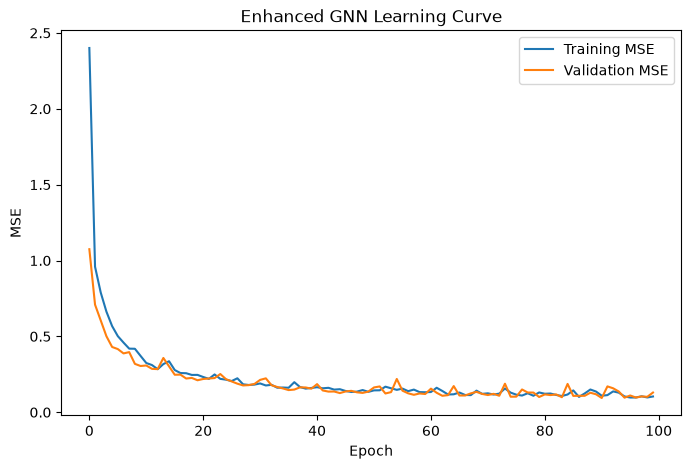

In [123]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    train_history,
    label="Training MSE"
)

plt.plot(
    val_history,
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Enhanced GNN Learning Curve")
plt.legend()
plt.show()

In [124]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

enhanced_model.eval()

y_true_enh = []
y_pred_enh = []

with torch.no_grad():

    for x, edge_index, edge_attr, batch_ids, y in test_loader_enhanced:

        pred_scaled = enhanced_model(
            x,
            edge_index,
            edge_attr,
            batch_ids
        )

        # 恢复原始 logS 单位
        pred = (
            pred_scaled * y_std_enh
            + y_mean_enh
        )

        y_true_enh.extend(
            y.numpy().tolist()
        )

        y_pred_enh.extend(
            pred.numpy().tolist()
        )

enhanced_mae = mean_absolute_error(
    y_true_enh, y_pred_enh
)

enhanced_rmse = mean_squared_error(
    y_true_enh, y_pred_enh
) ** 0.5

enhanced_r2 = r2_score(
    y_true_enh, y_pred_enh
)

print("Enhanced GNN Test Results")
print("MAE:", enhanced_mae)
print("RMSE:", enhanced_rmse)
print("R2:", enhanced_r2)

Enhanced GNN Test Results
MAE: 0.6182728356360334
RMSE: 0.838698808877702
R2: 0.8511857536420024


In [125]:
import copy
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def train_and_evaluate(data, input_dim, seed):

    torch.manual_seed(seed)

    def make_loader(indices, shuffle=False):
        return DataLoader(
            Subset(data, indices.tolist()),
            batch_size=32,
            shuffle=shuffle,
            collate_fn=collate_bond_graphs,
            generator=torch.Generator().manual_seed(seed)
        )

    train_loader = make_loader(train_idx, True)
    val_loader = make_loader(val_idx)
    test_loader = make_loader(test_idx)

    model = BondAwareGNN(
        input_dim=input_dim,
        bond_dim=4,
        hidden_dim=32
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    criterion = nn.MSELoss()

    # 只使用训练集计算标签标准化参数
    y_mean = float(labels[train_idx].mean())
    y_std = float(labels[train_idx].std())

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    for epoch in range(1, 101):

        model.train()

        for x, edge_index, edge_attr, batch_ids, y in train_loader:

            optimizer.zero_grad()

            pred = model(
                x, edge_index, edge_attr, batch_ids
            )

            y_scaled = (y - y_mean) / y_std
            loss = criterion(pred, y_scaled)

            loss.backward()
            optimizer.step()

        # Validation
        model.eval()
        val_total = 0

        with torch.no_grad():
            for x, edge_index, edge_attr, batch_ids, y in val_loader:

                pred = model(
                    x, edge_index, edge_attr, batch_ids
                )

                y_scaled = (y - y_mean) / y_std
                loss = criterion(pred, y_scaled)

                val_total += loss.item() * len(y)

        val_loss = val_total / len(val_idx)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1

        if wait >= 15:
            break

    model.load_state_dict(best_state)
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for x, edge_index, edge_attr, batch_ids, y in test_loader:

            pred = model(
                x, edge_index, edge_attr, batch_ids
            )

            pred = pred * y_std + y_mean

            y_true.extend(y.numpy().tolist())
            y_pred.extend(pred.numpy().tolist())

    return {
        "Seed": seed,
        "Best Epoch": best_epoch,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred)
    }

In [126]:
import pandas as pd

seeds = [42, 123, 2026]

results = []

for seed in seeds:

    basic_result = train_and_evaluate(
        data=dataset,
        input_dim=10,
        seed=seed
    )

    basic_result["Model"] = "Bond-aware"
    results.append(basic_result)

    enhanced_result = train_and_evaluate(
        data=enhanced_dataset,
        input_dim=21,
        seed=seed
    )

    enhanced_result["Model"] = "Enhanced"
    results.append(enhanced_result)

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 Seed  Best Epoch      MAE     RMSE       R2      Model
   42          99 0.658583 0.869717 0.839975 Bond-aware
   42          64 0.652502 0.866011 0.841336   Enhanced
  123         100 0.700301 0.909474 0.825010 Bond-aware
  123          99 0.582509 0.785324 0.869524   Enhanced
 2026          86 0.694449 0.902057 0.827853 Bond-aware
 2026          53 0.651737 0.838842 0.851135   Enhanced


In [127]:
summary = (
    results_df
    .groupby("Model")[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
)

print(summary.round(4))

               MAE            RMSE              R2        
              mean     std    mean     std    mean     std
Model                                                     
Bond-aware  0.6844  0.0226  0.8937  0.0211  0.8309  0.0079
Enhanced    0.6289  0.0402  0.8301  0.0411  0.8540  0.0143
